In [1]:
!pip -q install tensorflow scikit-learn pandas numpy matplotlib seaborn gradio

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/student-por.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "student-por.csv was not found. "
        "Upload it using the Files panel on the left."
    )

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFinal grade statistics:")
print(df["G3"].describe())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardi

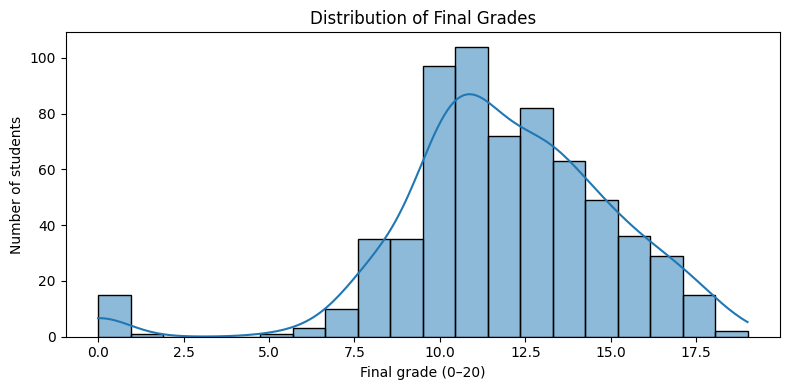

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="G3", bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

Pass/fail counts:
Pass
Pass    549
Fail    100
Name: count, dtype: int64


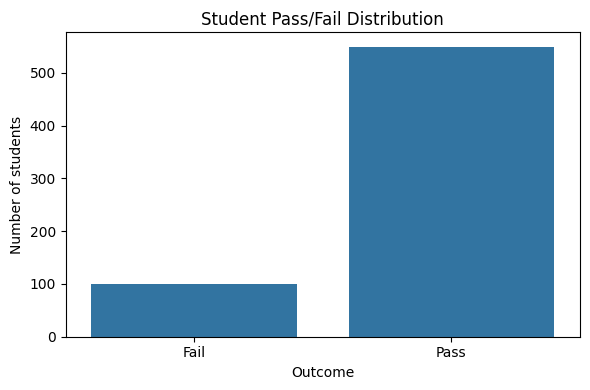

In [9]:
df["Pass"] = (df["G3"] >= 10).astype(int)

print("Pass/fail counts:")
print(df["Pass"].value_counts().rename(
    index={0: "Fail", 1: "Pass"}
))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Pass")
plt.xticks([0, 1], ["Fail", "Pass"])
plt.title("Student Pass/Fail Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

feature_columns = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "age",
    "schoolsup",
    "higher",
    "internet"
]

X = df[feature_columns].copy()
y = df["Pass"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", feature_columns)

Training samples: 519
Testing samples: 130
Input features: ['studytime', 'failures', 'absences', 'G1', 'G2', 'age', 'schoolsup', 'higher', 'internet']


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "studytime", "failures", "absences",
    "G1", "G2", "age"
]

categorical_features = [
    "schoolsup", "higher", "internet"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

X_train_raw = preprocessor.fit_transform(X_train)
X_test_raw = preprocessor.transform(X_test)

# Convert sparse or dense output into dense float32 arrays for TensorFlow
X_train_processed = (
    X_train_raw.toarray()
    if hasattr(X_train_raw, "toarray")
    else X_train_raw
).astype(np.float32)

X_test_processed = (
    X_test_raw.toarray()
    if hasattr(X_test_raw, "toarray")
    else X_test_raw
).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (519, 12)
Processed test shape: (130, 12)


In [12]:
%pip -q install tensorflow

In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train_np,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5566 - loss: 0.7116 - val_accuracy: 0.6635 - val_loss: 0.6420
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6458 - loss: 0.6367 - val_accuracy: 0.8173 - val_loss: 0.5805
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7687 - loss: 0.5763 - val_accuracy: 0.8558 - val_loss: 0.5307
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8386 - loss: 0.5249 - val_accuracy: 0.8750 - val_loss: 0.4875
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8602 - loss: 0.4804 - val_accuracy: 0.8750 - val_loss: 0.4488
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8651 - loss: 0.4413 - val_accuracy: 0.8750 - val_loss: 0.4136
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8843 - loss: 0.4062 - val_accuracy: 0.8846 - val_loss: 0.3816
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8916 - loss: 0.3748 - val_accuracy: 0.8942 - 

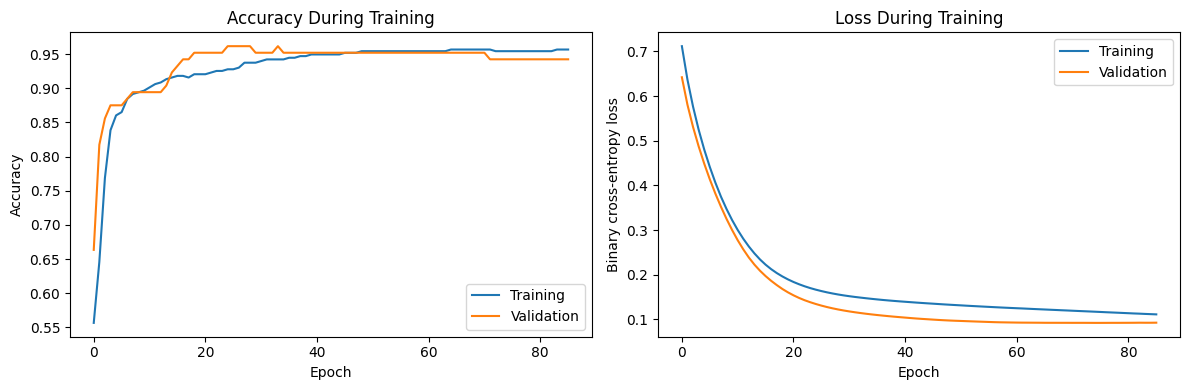

In [15]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["accuracy"], label="Training")
axes[0].plot(history_df["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy During Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training")
axes[1].plot(history_df["val_loss"], label="Validation")
axes[1].set_title("Loss During Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary cross-entropy loss")
axes[1].legend()

plt.tight_layout()
plt.show()

Test accuracy: 0.9077
Test precision: 0.9455
Test recall: 0.9455
Test F1-score: 0.9455

Classification report:
              precision    recall  f1-score   support

        Fail       0.70      0.70      0.70        20
        Pass       0.95      0.95      0.95       110

    accuracy                           0.91       130
   macro avg       0.82      0.82      0.82       130
weighted avg       0.91      0.91      0.91       130



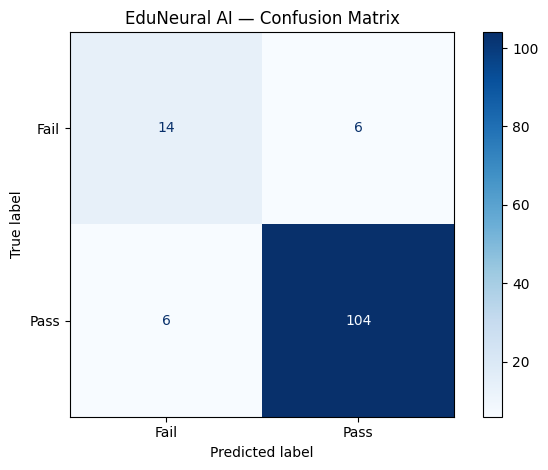

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

test_probabilities = model.predict(
    X_test_processed,
    verbose=0
).ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

print("Test accuracy:",
      round(accuracy_score(y_test_np, test_predictions), 4))

print("Test precision:",
      round(precision_score(y_test_np, test_predictions, zero_division=0), 4))

print("Test recall:",
      round(recall_score(y_test_np, test_predictions, zero_division=0), 4))

print("Test F1-score:",
      round(f1_score(y_test_np, test_predictions, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_test_np,
    test_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_np,
    test_predictions,
    display_labels=["Fail", "Pass"],
    cmap="Blues"
)
plt.title("EduNeural AI — Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ])),
    ("classifier", LogisticRegression(max_iter=2000))
])

baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "F1-score": f1_score(
            y_test, baseline_predictions, zero_division=0
        )
    },
    {
        "Model": "Neural Network",
        "Accuracy": accuracy_score(y_test_np, test_predictions),
        "F1-score": f1_score(
            y_test_np, test_predictions, zero_division=0
        )
    }
])

display(comparison.round(4))

,Model,Accuracy,F1-score
0,Logistic Regression,0.8923,0.9369
1,Neural Network,0.9077,0.9455


In [18]:
tf.keras.utils.set_random_seed(42)

tanh_model = keras.Sequential([
    keras.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(16, activation="tanh"),
    layers.Dense(8, activation="tanh"),
    layers.Dense(1, activation="sigmoid")
])

tanh_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tanh_history = tanh_model.fit(
    X_train_processed,
    y_train_np,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=0
)

tanh_probabilities = tanh_model.predict(
    X_test_processed,
    verbose=0
).ravel()

tanh_predictions = (tanh_probabilities >= 0.5).astype(int)

activation_comparison = pd.DataFrame([
    {
        "Activation": "ReLU",
        "Accuracy": accuracy_score(y_test_np, test_predictions),
        "F1-score": f1_score(
            y_test_np, test_predictions, zero_division=0
        )
    },
    {
        "Activation": "tanh",
        "Accuracy": accuracy_score(y_test_np, tanh_predictions),
        "F1-score": f1_score(
            y_test_np, tanh_predictions, zero_division=0
        )
    }
])

display(activation_comparison.round(4))

,Activation,Accuracy,F1-score
0,ReLU,0.9077,0.9455
1,tanh,0.9077,0.9455


In [19]:
%pip -q install gradio

In [20]:
import gradio as gr

def predict_student(
    studytime,
    failures,
    absences,
    G1,
    G2,
    age,
    schoolsup,
    higher,
    internet
):
    student = pd.DataFrame([{
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "G1": G1,
        "G2": G2,
        "age": age,
        "schoolsup": schoolsup,
        "higher": higher,
        "internet": internet
    }])[feature_columns]

    transformed = preprocessor.transform(student)

    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()

    transformed = np.asarray(transformed, dtype=np.float32)

    probability = float(
        model.predict(transformed, verbose=0).ravel()[0]
    )

    outcome = "PASS" if probability >= 0.5 else "FAIL"

    return (
        f"Predicted outcome: {outcome}",
        f"Estimated pass probability: {probability:.1%}\n"
        f"Estimated fail probability: {1 - probability:.1%}\n\n"
        "This is an educational model estimate, not a guarantee "
        "of academic performance."
    )

demo = gr.Interface(
    fn=predict_student,
    inputs=[
        gr.Slider(1, 4, value=2, step=1, label="Study time (1–4)"),
        gr.Slider(0, 4, value=0, step=1, label="Past class failures"),
        gr.Number(value=2, label="School absences"),
        gr.Slider(0, 20, value=10, step=1, label="First-period grade (G1)"),
        gr.Slider(0, 20, value=10, step=1, label="Second-period grade (G2)"),
        gr.Slider(15, 22, value=17, step=1, label="Age"),
        gr.Radio(["yes", "no"], value="no", label="Extra school support"),
        gr.Radio(["yes", "no"], value="yes", label="Wants higher education"),
        gr.Radio(["yes", "no"], value="yes", label="Internet at home")
    ],
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Model output", lines=4)
    ],
    title="EduNeural AI — Student Performance Predictor",
    description=(
        "Experiment with student characteristics and earlier grades "
        "to explore the model's predicted pass/fail outcome."
    )
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://43f1df0e89e913d0f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://43f1df0e89e913d0f3.gradio.live
